In [18]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# --- SVM One-Shot Revision ---
data = load_breast_cancer()
X, y = data.data, data.target
sc = StandardScaler()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)
for kernel in ['linear', 'rbf']:
    m = SVC(kernel=kernel, random_state=42)
    m.fit(X_train, y_train)
    print(f'{kernel}: {accuracy_score(y_test, m.predict(X_test)):.4f}')

# VIVA NOTES:
# 1. Kernel trick maps data to high-dim space without explicit computation (RBF, poly, etc.)
# 2. C = regularization - high C means low bias, high variance (fits training more)
# 3. gamma (RBF) = inverse radius - high gamma means tight boundary (overfitting)
# 4. Always scale features before SVM (sensitive to feature magnitude)
# 5. SVMs maximize margin between classes using support vectors only
# 6. Multiclass SVM uses OvO (one-vs-one) by default in sklearn


linear: 0.9561
rbf: 0.9825


### Q7
Consider Social_Network_Ads.csv dataset - (UserID, Gender, Age, EstimatedSalary, Purchased). Use Age and EstimatedSalary as input features and Purchased as target feature. Split test data set 30% of complete dataset. Build two models of support vector classifier in python using sklearn library, one for linear and another for RBF kernel with C and gamma parameters set. Predict test labels and print test accuracy.

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score


In [20]:
# Load dataset - use Age and EstimatedSalary as features, Purchased as target
df = pd.read_csv('datasets/Social_Network_Ads.csv')
print(df.head())
print(f'Shape: {df.shape}')
X = df[['Age', 'EstimatedSalary']].values
y = df['Purchased'].values


    User ID  Gender  Age  EstimatedSalary  Purchased
0  15624510    Male   19            19000          0
1  15810944    Male   35            20000          0
2  15668575  Female   26            43000          0
3  15603246  Female   27            57000          0
4  15804002    Male   19            76000          0
Shape: (400, 5)


In [21]:
# 70/30 split, then scale features (SVM is sensitive to scale)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)
print(f'Train: {X_train.shape}, Test: {X_test.shape}')


Train: (280, 2), Test: (120, 2)


In [22]:
# Linear SVC
model_lin = SVC(kernel='linear', C=1, random_state=42)
model_lin.fit(X_train, y_train)
y_pred_lin = model_lin.predict(X_test)
print(f'Linear SVC Accuracy: {accuracy_score(y_test, y_pred_lin):.4f}')

# RBF SVC
model_rbf = SVC(kernel='rbf', C=1, gamma=0.1, random_state=42)
model_rbf.fit(X_train, y_train)
y_pred_rbf = model_rbf.predict(X_test)
print(f'RBF SVC Accuracy: {accuracy_score(y_test, y_pred_rbf):.4f}')


Linear SVC Accuracy: 0.8500
RBF SVC Accuracy: 0.9333


### Q8
Develop a Support Vector Classifier to predict whether a tumor is malignant or benign based on 30 features computed from a digitized image of a fine needle aspirate (FNA) of a breast mass. The dataset contains 569 samples with binary labels indicating tumor type (breast_cancer dataset of sklearn). Load the dataset from sklearn. Split the dataset into training and testing sets. Train the SVC model using the training data. Visualize the results.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.decomposition import PCA


In [24]:
# Load breast cancer dataset (569 samples, 30 features, binary: malignant/benign)
data = load_breast_cancer()
X, y = data.data, data.target
print(f'Shape: {X.shape}, Classes: {data.target_names}')


Shape: (569, 30), Classes: ['malignant' 'benign']


In [25]:
# 80/20 split, scale features before SVM
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

model = SVC(kernel='rbf', random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(f'Accuracy: {accuracy_score(y_test, y_pred):.4f}')
print(classification_report(y_test, y_pred, target_names=data.target_names))


Accuracy: 0.9825
              precision    recall  f1-score   support

   malignant       1.00      0.95      0.98        43
      benign       0.97      1.00      0.99        71

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



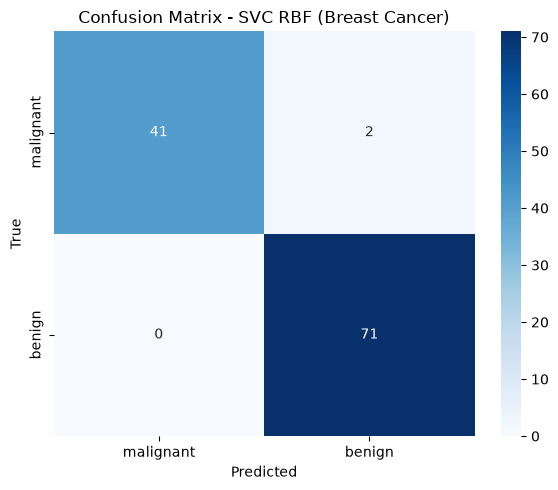

In [ ]:
# (a) Confusion matrix heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=data.target_names, yticklabels=data.target_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix - SVC RBF (Breast Cancer)')
plt.tight_layout()
plt.show()


### Q9
Implement an SVC model to classify iris flowers into three species (Setosa, Versicolor, and Virginica) based on their sepal and petal dimensions. The dataset contains 150 samples with four features: sepal length, sepal width, petal length, and petal width. Load the dataset from sklearn. Split the dataset into training and testing sets. Train the SVC model using the training data. Visualize the results.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix


In [29]:
# Load Iris dataset (150 samples, 4 features, 3 classes)
data = load_iris()
X, y = data.data, data.target
print(f'Shape: {X.shape}, Classes: {data.target_names}')


Shape: (150, 4), Classes: ['setosa' 'versicolor' 'virginica']


In [ ]:
# 80/20 split, scale features
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

model = SVC(kernel='rbf', C=1, gamma='scale', random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(f'Accuracy: {accuracy_score(y_test, y_pred):.4f}')


Accuracy: 1.0000


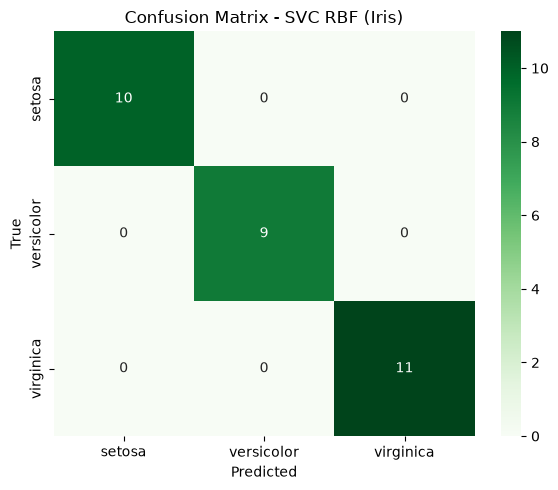

In [31]:
# (a) Confusion matrix heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=data.target_names, yticklabels=data.target_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix - SVC RBF (Iris)')
plt.tight_layout()
plt.show()
